In [1]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score


In [2]:
data = pd.read_csv(r"E:\BE\Practical\ML_Practical\Practical_1\uber.csv")

In [3]:
df = data.copy()

In [4]:
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB


In [6]:
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"])

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype              
---  ------             --------------   -----              
 0   Unnamed: 0         200000 non-null  int64              
 1   key                200000 non-null  object             
 2   fare_amount        200000 non-null  float64            
 3   pickup_datetime    200000 non-null  datetime64[ns, UTC]
 4   pickup_longitude   200000 non-null  float64            
 5   pickup_latitude    200000 non-null  float64            
 6   dropoff_longitude  199999 non-null  float64            
 7   dropoff_latitude   199999 non-null  float64            
 8   passenger_count    200000 non-null  int64              
dtypes: datetime64[ns, UTC](1), float64(5), int64(2), object(1)
memory usage: 13.7+ MB


In [8]:
df.describe()

,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


In [9]:
df = df.drop(columns=["Unnamed: 0", "key"], errors="ignore")

In [10]:
df = df[df["fare_amount"] > 0]

df = df[df["passenger_count"].between(1, 6)]

In [11]:
df.isnull().sum()

fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64

In [12]:
df.corr(numeric_only=True)

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
fare_amount,1.000000,0.010420,-0.008441,0.009064,-0.011099,0.010175
pickup_longitude,0.010420,1.000000,-0.815878,0.833047,-0.846383,-0.000164
pickup_latitude,-0.008441,-0.815878,1.000000,-0.774615,0.701959,-0.001882
dropoff_longitude,0.009064,0.833047,-0.774615,1.000000,-0.916715,0.000163
dropoff_latitude,-0.011099,-0.846383,0.701959,-0.916715,1.000000,-0.000825
passenger_count,0.010175,-0.000164,-0.001882,0.000163,-0.000825,1.000000


In [13]:
df.dropna(inplace=True)

{'whiskers': [<matplotlib.lines.Line2D at 0x1f27b957110>,
 'caps': [<matplotlib.lines.Line2D at 0x1f27b957390>,
 'boxes': [<matplotlib.lines.Line2D at 0x1f27664afd0>],
 'medians': [<matplotlib.lines.Line2D at 0x1f27b957610>],
 'fliers': [<matplotlib.lines.Line2D at 0x1f27b957750>],
 'means': []}

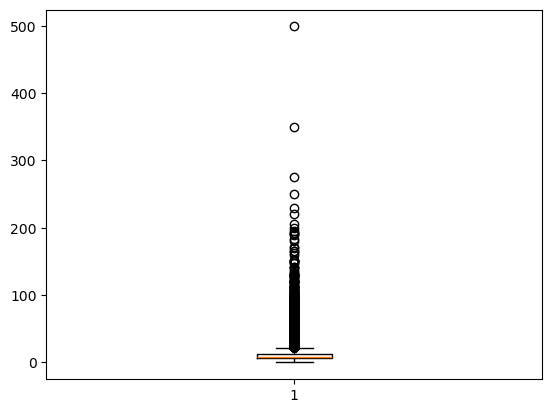

In [14]:
plt.boxplot(df['fare_amount'])

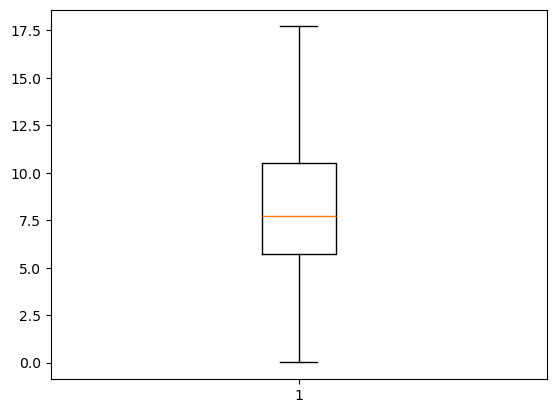

In [15]:
while True:
    Q1 = df["fare_amount"].quantile(0.25)
    Q3 = df["fare_amount"].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    new_df = df[
        (df["fare_amount"] >= lower_limit) &
        (df["fare_amount"] <= upper_limit)
    ]

    if len(new_df) == len(df):
        break

    df = new_df

plt.boxplot(df["fare_amount"])
plt.show()

In [16]:
df.isnull().sum()

fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64

In [17]:
#Take x as predictor variable
x = df.drop("fare_amount", axis = 1)
#And y as target variable
y = df['fare_amount']


In [18]:

# Convert pickup_datetime into a numerical value
x['pickup_datetime'] = pd.to_datetime(x['pickup_datetime'], utc=True)

x['pickup_datetime'] = (
    x['pickup_datetime'].astype('int64') // 10**9
)


In [19]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 1)

In [20]:
lrmodel = LinearRegression()
lrmodel.fit(x_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [21]:
#Prediction
predict = lrmodel.predict(x_test)

In [22]:

# Check Error for Linear Regression
lrmodelrmse = np.sqrt(mean_squared_error(y_test, predict))
lrmodelr2 = r2_score(y_test, predict)

print("Linear Regression RMSE:", lrmodelrmse)
print("Linear Regression R2 Score:", lrmodelr2)


Linear Regression RMSE: 3.4300336353531082
Linear Regression R2 Score: 0.017131283903567995


In [23]:
#Let's Apply Random Forest Regressor
rfrmodel = RandomForestRegressor(n_estimators = 100, random_state = 101)

In [24]:
#Fit the Forest
rfrmodel.fit(x_train, y_train)
rfrmodel_pred = rfrmodel.predict(x_test)

In [25]:

# Check Errors for Random Forest
rfrmodel_rmse = np.sqrt(mean_squared_error(y_test, rfrmodel_pred))
rfrmodel_r2 = r2_score(y_test, rfrmodel_pred)

print("Random Forest RMSE:", rfrmodel_rmse)
print("Random Forest R2 Score:", rfrmodel_r2)


Random Forest RMSE: 1.853765314785321
Random Forest R2 Score: 0.7129164828085155
